# BAIR world model — 2. Single-step and multi-step training

**Draft implementation; no trained results are claimed.** This notebook implements the proposal's convolutional encoder-decoder in PyTorch and trains two versions with the same architecture and initialization:

1. **Model A:** one-step MSE from three real context frames.
2. **Model B:** five-step open-loop rollout MSE; predictions replace observed frames and gradients flow through the full unroll.

The baseline copies the final observed frame and has no training phase. Both learned models consume the action for each predicted transition. We use the mean over rollout steps, which differs from a sum only by a constant scale and keeps loss magnitudes comparable. This is full self-feeding after the initial context, rather than a scheduled-sampling mixture.

Run notebook 01 first. Default settings are an initial experiment, not a convergence guarantee. Model B costs more per optimization step; compare both optimizer updates and wall-clock time. Tune settings using validation clips, then evaluate the test set once.

In [1]:
from pathlib import Path
import json, random, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Run from the repository root or its notebooks/ directory.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "processed" / "bair_hf_aux1_v1"
ARTIFACTS = ROOT / "artifacts" / "bair_hf_aux1_v1"
SEED = 4620
random.seed(SEED)
np.random.seed(SEED)

In [2]:
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
torch.set_num_threads(min(4, torch.get_num_threads()))
DEVICE = torch.device("cuda" if torch.cuda.is_available() else
                      "mps" if torch.backends.mps.is_available() else "cpu")
print("Device:", DEVICE, "| PyTorch:", torch.__version__)
if not (DATA / "manifest.csv").exists():
    raise FileNotFoundError("Run notebook 01 on real BAIR data before continuing.")
manifest = pd.read_csv(DATA / "manifest.csv")
metadata = json.loads((DATA / "metadata.json").read_text())
MANIFEST_HASH = hashlib.sha256((DATA / "manifest.csv").read_bytes()).hexdigest()
assert MANIFEST_HASH == metadata["manifest_sha256"]
with np.load(DATA / "action_stats.npz", allow_pickle=False) as stats:
    ACTION_MEAN, ACTION_STD = stats["mean"].copy(), stats["std"].copy()
CONTEXT, ACTION_DIM = 3, 4

Device: mps | PyTorch: 2.9.1


## Sequence windows and temporal indexing

For context `[I0, I1, I2]`, the first prediction uses `a2` to target `I3`; the second uses `a3` to target `I4`. Training enumerates every valid window. Both models use the same five-step training-window population, even though Model A's loss uses only its first target. Validation uses one fixed window per clip to avoid treating overlapping windows as independent observations.

In [3]:
class BAIRWindows(Dataset):
    """All valid windows for training; one fixed start per clip for evaluation."""
    def __init__(self, split, horizon, all_windows=False):
        self.horizon = horizon
        self.items = []
        rows = manifest[manifest.split.eq(split)].sort_values("clip_id")
        for row in rows.itertuples():
            count = int(row.frames) - CONTEXT - horizon + 1
            if count < 1:
                raise ValueError(f"Clip {row.clip_id} too short for horizon {horizon}")
            for start in (range(count) if all_windows else [0]):
                self.items.append((row.path, start, row.clip_id))
        if not self.items:
            raise ValueError(f"No {split} windows. Check the manifest.")

    def __len__(self):
        return len(self.items)

    def __getitem__(self, index):
        path, start, clip_id = self.items[index]
        with np.load(DATA / path, allow_pickle=False) as clip:
            frames = clip["frames"][start:start + CONTEXT + self.horizon].copy()
            # Last observed frame is at start+2; a[start+2] predicts frame[start+3].
            a0 = start + CONTEXT - 1
            actions = clip["actions"][a0:a0 + self.horizon].copy()
        frames = torch.from_numpy(frames).permute(0, 3, 1, 2).float() / 255.0
        actions = torch.from_numpy((actions - ACTION_MEAN) / ACTION_STD)
        assert len(actions) == self.horizon
        return {"context": frames[:CONTEXT], "actions": actions,
                "target": frames[CONTEXT:], "clip_id": clip_id}

def make_loader(split, horizon, batch_size, train=False, seed=SEED):
    return DataLoader(BAIRWindows(split, horizon, all_windows=train),
                      batch_size=batch_size, shuffle=train, num_workers=0,
                      generator=torch.Generator().manual_seed(seed),
                      pin_memory=DEVICE.type == "cuda")

## Action-conditioned encoder-decoder

Three RGB frames become nine input channels. The encoder reduces spatial resolution to 8×8. A learned action vector is broadcast across that grid and fused with visual features; the decoder predicts RGB values in `[0,1]`. No pretrained weights or physical state labels are used.

In [4]:
class ActionVideoModel(nn.Module):
    def __init__(self, width=32):
        super().__init__()
        self.width = width
        self.encoder = nn.Sequential(
            nn.Conv2d(9, width, 4, 2, 1), nn.ReLU(),
            nn.Conv2d(width, width * 2, 4, 2, 1), nn.ReLU(),
            nn.Conv2d(width * 2, width * 4, 4, 2, 1), nn.ReLU())
        self.action_encoder = nn.Sequential(nn.Linear(ACTION_DIM, width), nn.ReLU())
        self.fuse = nn.Sequential(nn.Conv2d(width * 5, width * 4, 3, padding=1), nn.ReLU())
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(width * 4, width * 2, 4, 2, 1), nn.ReLU(),
            nn.ConvTranspose2d(width * 2, width, 4, 2, 1), nn.ReLU(),
            nn.ConvTranspose2d(width, 3, 4, 2, 1), nn.Sigmoid())

    def forward(self, context, action):
        b, t, c, h, w = context.shape
        assert (t, c, h, w) == (3, 3, 64, 64)
        visual = self.encoder(context.reshape(b, t * c, h, w))
        action_map = self.action_encoder(action)[:, :, None, None]
        action_map = action_map.expand(-1, -1, visual.shape[-2], visual.shape[-1])
        return self.decoder(self.fuse(torch.cat([visual, action_map], dim=1)))

def rollout(model, context, actions):
    history, predictions = context, []
    for step in range(actions.shape[1]):
        prediction = model(history, actions[:, step])
        predictions.append(prediction)
        # Preserve the graph: multi-step training backpropagates through predictions.
        history = torch.cat([history[:, 1:], prediction[:, None]], dim=1)
    return torch.stack(predictions, dim=1)

In [5]:
from datetime import datetime, timezone
import time

CONFIG = dict(seed=SEED, width=32, batch_size=32, epochs=10,
              learning_rate=1e-3, train_horizon=5, validation_horizon=10,
              max_batches_per_epoch=None, gradient_clip=1.0)
# Use a fresh run directory; prior checkpoints are preserved.
RUN_ID = datetime.now(timezone.utc).strftime("run_%Y%m%dT%H%M%S_%fZ")
RUN = ARTIFACTS / RUN_ID
RUN.mkdir(parents=True, exist_ok=False)
CONFIG.update(manifest_sha256=MANIFEST_HASH, camera=metadata["camera"],
              torch_version=str(torch.__version__), device=str(DEVICE))
(RUN / "config.json").write_text(json.dumps(CONFIG, indent=2))
print("Run outputs:", RUN)

# A shape check using real BAIR data; no fabricated training examples.
batch = next(iter(make_loader("train", CONFIG["train_horizon"], 2)))
probe = ActionVideoModel(CONFIG["width"]).to(DEVICE)
with torch.no_grad():
    prediction = rollout(probe, batch["context"].to(DEVICE), batch["actions"].to(DEVICE))
assert prediction.shape == batch["target"].shape
assert torch.isfinite(prediction).all()
print("Context:", tuple(batch["context"].shape), "| Predictions:", tuple(prediction.shape))
del probe, prediction

Run outputs: /Users/aakash/Documents/DATA 4620/Project /artifacts/bair_hf_aux1_v1/run_20261117T163624_197610Z
Context: (2, 3, 3, 64, 64) | Predictions: (2, 5, 3, 64, 64)


## Training and checkpoint selection

Both models start from identical parameters. Each uses a fresh optimizer and the same seeded window order. Checkpoints are selected by **validation open-loop MSE at horizon 10**, regardless of training objective. The test set is never loaded during training. Checkpoints include configuration and action statistics so evaluation can reject mismatched data.

In [6]:
@torch.no_grad()
def validation_mse(model, loader):
    model.eval()
    total, count = 0.0, 0
    for batch in loader:
        pred = rollout(model, batch["context"].to(DEVICE), batch["actions"].to(DEVICE))
        target = batch["target"].to(DEVICE)
        # Endpoint horizon 10 is the preregistered checkpoint-selection metric.
        per_clip = (pred[:, -1] - target[:, -1]).square().mean(dim=(1, 2, 3))
        total += per_clip.sum().item()
        count += len(per_clip)
    return total / count

torch.manual_seed(SEED)
initial = ActionVideoModel(CONFIG["width"])
initial_state = {k: v.detach().cpu().clone() for k, v in initial.state_dict().items()}
del initial

def train_model(name, loss_horizon):
    torch.manual_seed(SEED)
    model = ActionVideoModel(CONFIG["width"]).to(DEVICE)
    model.load_state_dict(initial_state)
    optimizer = torch.optim.Adam(model.parameters(), lr=CONFIG["learning_rate"])
    train_loader = make_loader("train", CONFIG["train_horizon"], CONFIG["batch_size"], train=True)
    val_loader = make_loader("val", CONFIG["validation_horizon"], CONFIG["batch_size"])
    history, best, updates = [], float("inf"), 0
    started = time.perf_counter()
    for epoch in range(1, CONFIG["epochs"] + 1):
        model.train()
        loss_sum, count = 0.0, 0
        for batch_number, batch in enumerate(train_loader):
            cap = CONFIG["max_batches_per_epoch"]
            if cap is not None and batch_number >= cap:
                break
            context = batch["context"].to(DEVICE)
            actions = batch["actions"][:, :loss_horizon].to(DEVICE)
            target = batch["target"][:, :loss_horizon].to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            pred = rollout(model, context, actions)
            loss = (pred - target).square().mean()
            if not torch.isfinite(loss):
                raise FloatingPointError(f"Non-finite loss for {name} at epoch {epoch}")
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), CONFIG["gradient_clip"])
            optimizer.step()
            loss_sum += loss.item() * len(context)
            count += len(context)
            updates += 1
        if count == 0:
            raise ValueError("No training batches were processed.")
        val = validation_mse(model, val_loader)
        row = dict(model=name, epoch=epoch, train_mse=loss_sum / count,
                   val_h10_mse=val, updates=updates,
                   elapsed_seconds=time.perf_counter() - started)
        history.append(row)
        print(row)
        if val < best:
            best = val
            torch.save({"model_state": {k: v.detach().cpu() for k, v in model.state_dict().items()},
                        "config": CONFIG, "model_name": name, "loss_horizon": loss_horizon,
                        "epoch": epoch, "val_h10_mse": val,
                        "action_mean": ACTION_MEAN.tolist(), "action_std": ACTION_STD.tolist()},
                       RUN / f"{name}_best.pt")
        pd.DataFrame(history).to_csv(RUN / f"{name}_history.csv", index=False)
    return pd.DataFrame(history)

{'model': 'model_a_single_step', 'epoch': 1, 'train_mse': 0.015953165247388507, 'val_h10_mse': 0.03793198794126511, 'updates': 647, 'elapsed_seconds': 137.71228950005025}
{'model': 'model_a_single_step', 'epoch': 2, 'train_mse': 0.008297561152167798, 'val_h10_mse': 0.023991132974624633, 'updates': 1294, 'elapsed_seconds': 282.8820741248783}
{'model': 'model_a_single_step', 'epoch': 3, 'train_mse': 0.007003795728267391, 'val_h10_mse': 0.029036933034658433, 'updates': 1941, 'elapsed_seconds': 406.88204120798036}
{'model': 'model_a_single_step', 'epoch': 4, 'train_mse': 0.006370752873664029, 'val_h10_mse': 0.025034809559583662, 'updates': 2588, 'elapsed_seconds': 530.9859716659412}
{'model': 'model_a_single_step', 'epoch': 5, 'train_mse': 0.005945709445086367, 'val_h10_mse': 0.027389521524310113, 'updates': 3235, 'elapsed_seconds': 659.1319179160055}
{'model': 'model_a_single_step', 'epoch': 6, 'train_mse': 0.0056602450682453195, 'val_h10_mse': 0.027726005911827088, 'updates': 3882, 'elap

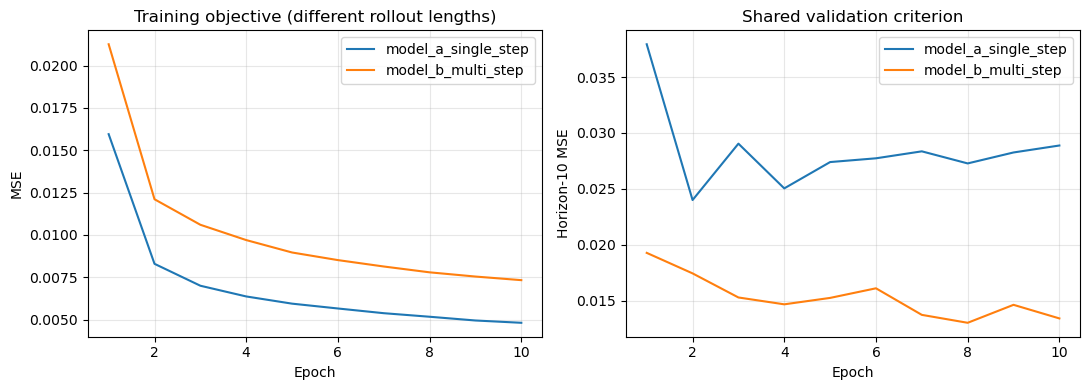

Copy this run path into notebook 03: /Users/aakash/Documents/DATA 4620/Project /artifacts/bair_hf_aux1_v1/run_20261117T163624_197610Z


In [7]:
history_a = train_model("model_a_single_step", loss_horizon=1)
history_b = train_model("model_b_multi_step", loss_horizon=CONFIG["train_horizon"])
history = pd.concat([history_a, history_b], ignore_index=True)
history.to_csv(RUN / "training_history.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, group in history.groupby("model"):
    axes[0].plot(group.epoch, group.train_mse, label=name)
    axes[1].plot(group.epoch, group.val_h10_mse, label=name)
axes[0].set(title="Training objective (different rollout lengths)", xlabel="Epoch", ylabel="MSE")
axes[1].set(title="Shared validation criterion", xlabel="Epoch", ylabel="Horizon-10 MSE")
for ax in axes:
    ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print("Copy this run path into notebook 03:", RUN)

## Training notes for the first report

Record actual data counts, hardware, epochs, optimizer updates, elapsed time, selected epoch, and any caps. Investigate divergence, blurred predictions, and failure to beat persistence using validation data. Repeat final configurations with multiple seeds before making strong comparative claims.

**Pending:** trained checkpoints, learning curves, and conclusions require running this notebook on BAIR. Next run notebook 03 with the explicit run directory printed above.